In [151]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report   #for classification report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from sklearn.model_selection import train_test_split

from PIL import Image   #for image processing
from torchvision.models.vision_transformer import vit_b_16 # our ViT model
import torch 
import torchvision.transforms as transforms #transformations to apply to the image
from torch.utils.data import DataLoader, Dataset, Subset #for creating our dataset and dataloader <-------- check this
import torch.nn as nn #for our neural network o modifying the head of the model

from torch.optim.lr_scheduler import CosineAnnealingLR

import torch.optim as optim #for our optimizer
import torch.nn.functional as F #for our loss function


from IPython.display import display, clear_output
from tqdm import tqdm



from functions import *

In [122]:
df = pd.read_csv("dataset.csv")
df.head()

,image,label
0,images/text2img/61/19242061_1982-08-16_2009.jpg,text2img
1,images/text2img/61/2399661_1977-09-02_2008.jpg,text2img
2,images/text2img/61/41899761_1989-10-06_2012.jpg,text2img
3,images/text2img/61/15330561_1943-08-11_2002.jpg,text2img
4,images/text2img/61/2075561_1966-06-14_2010.jpg,text2img


In [123]:
label_counts = df["label"].value_counts()
print(label_counts)

label
text2img      30000
insight       30000
wiki          30000
inpainting    30000
Name: count, dtype: int64


# Split

In [131]:
from sklearn.model_selection import train_test_split

# --- Parameters ---
n_train = 20000        # Total images for training
n_train_per_class = n_train // 2  # e.g., 10,000 from "wiki" and 10,000 from others
n_val = 4000           # Total images for validation
n_val_per_class = n_val // 2      # e.g., 2,000 from "wiki" and 2,000 from others

# --- Create Balanced Training Set ---
# 1) Sample half from 'wiki'
wiki_train = df[df["label"] == "wiki"].sample(n=n_train_per_class, random_state=42)

# 2) Sample half from the other labels
fake_train = df[df["label"].isin(["text2img", "insight", "inpainting"])].sample(n=n_train_per_class, 
                                                                               random_state=42)

# Combine these to form the training DataFrame
train_df = pd.concat([wiki_train, fake_train])
train_idx = train_df.index  # Keep track of which rows were used
train_df = train_df.reset_index(drop=True)

# --- Create Balanced Validation Set ---
# Exclude training samples
remaining_df = df.drop(train_idx)

# 1) Sample half of the validation set from 'wiki'
wiki_val = remaining_df[remaining_df["label"] == "wiki"].sample(n=n_val_per_class, random_state=42)

# 2) Sample half of the validation set from the other labels
fake_val = remaining_df[remaining_df["label"].isin(["text2img", "insight", "inpainting"])] \
                      .sample(n=n_val_per_class, random_state=42)

val_df = pd.concat([wiki_val, fake_val])
val_idx = val_df.index
val_df = val_df.reset_index(drop=True)

# --- Create Test Set ---
# Test set is everything else
test_df = df.drop(train_idx.union(val_idx)).reset_index(drop=True)

# --- Print sizes to verify ---
print("Training set size:", len(train_df))   # Expected: 20,000
print("Validation set size:", len(val_df))   # Expected: 4,000
print("Test set size:", len(test_df))        # Remaining images

# (Optional) Quick label distribution check
print("Train label distribution:\n", train_df["label"].value_counts())
print("Validation label distribution:\n", val_df["label"].value_counts())
print("Test label distribution:\n", test_df["label"].value_counts())

Training set size: 20000
Validation set size: 4000
Test set size: 96000
Train label distribution:
 label
wiki          10000
insight        3378
inpainting     3336
text2img       3286
Name: count, dtype: int64
Validation label distribution:
 label
wiki          2000
inpainting     684
insight        665
text2img       651
Name: count, dtype: int64
Test label distribution:
 label
text2img      26063
inpainting    25980
insight       25957
wiki          18000
Name: count, dtype: int64


In [132]:
#let's cheks
assert len(df) == len(train_df) + len(test_df) + len(val_df)

In [133]:
label_counts = train_df["label"].value_counts()
print(label_counts)

label
wiki          10000
insight        3378
inpainting     3336
text2img       3286
Name: count, dtype: int64


In [134]:
def map_labels(label):
    if label == "wiki":
        return 1
    else:
        return 0

train_df['label'] = train_df['label'].apply(map_labels)
val_df['label'] = val_df['label'].apply(map_labels)
test_df['label'] = test_df['label'].apply(map_labels)

In [135]:
label_counts = train_df["label"].value_counts()
print(label_counts)

label
1    10000
0    10000
Name: count, dtype: int64


In [136]:
label_counts = val_df["label"].value_counts()
print(label_counts)

label
1    2000
0    2000
Name: count, dtype: int64


In [138]:
label_counts = test_df["label"].value_counts()
print(label_counts)

label
0    78000
1    18000
Name: count, dtype: int64


In [139]:
def show_img(img_path):
    img = Image.open(img_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

# check df's

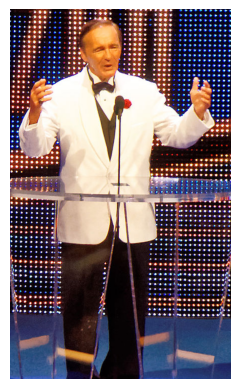

In [140]:
sample_image_path = train_df.iloc[0]["image"]
show_img(sample_image_path)

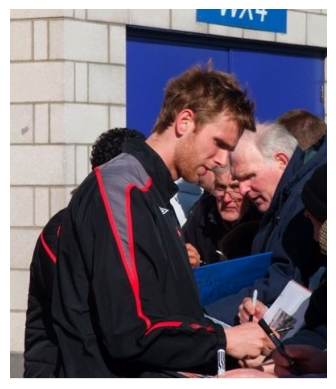

In [141]:
sample_image_path = val_df.iloc[0]["image"]
show_img(sample_image_path)


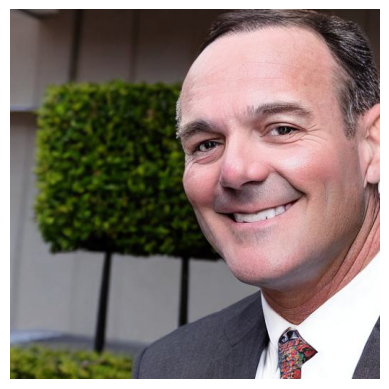

In [142]:
sample_image_path = test_df.iloc[0]["image"]
show_img(sample_image_path)

# image processig

In [143]:
transform = transforms.Compose([
    transforms.Resize(256, interpolation=transforms.InterpolationMode.BILINEAR),#  do not recise
    transforms.CenterCrop(224),
    transforms.ToTensor(),  # Converts to [0, 1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# MPS as device

In [144]:
# Check that MPS is available
if not torch.backends.mps.is_available():
    if not torch.backends.mps.is_built():
        print("MPS not available because the current PyTorch install was not "
              "built with MPS enabled.")
    else:
        print("MPS not available because the current MacOS version is not 12.3+ "
              "and/or you do not have an MPS-enabled device on this machine.")

else:
    print("MPS is available and enabled.")
    mps_device = torch.device("mps")

MPS is available and enabled.


# create Dataset

In [165]:
label_counts = test_df["label"].value_counts()
print(label_counts)

label
0    78000
1    18000
Name: count, dtype: int64


In [171]:
# Step 1: Separate the test samples by class
class_0 = test_df[test_df["label"] == 0]
class_1 = test_df[test_df["label"] == 1]

# Step 2: Undersample the majority class (class 0) to match the minority class (class 1)
n_samples = 10000
class_0_balanced = class_0.sample(n=n_samples, random_state=42)
class_1_balanced = class_1.sample(n=n_samples, random_state=42)

# Step 3: Combine the two balanced classes and shuffle
balanced_test_df = pd.concat([class_0_balanced, class_1_balanced], axis=0)
balanced_test_df = balanced_test_df.sample(frac=1, random_state=42).reset_index(drop=True)


In [172]:
label_counts = balanced_test_df["label"].value_counts()
print(label_counts)

label
1    10000
0    10000
Name: count, dtype: int64


In [173]:
label_counts = balanced_test_df["label"].value_counts()
print(label_counts)

label
1    10000
0    10000
Name: count, dtype: int64


In [174]:
class ImageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df  # Store the DataFrame
        self.transform = transform  # Store transformations

    def __len__(self):
        return len(self.df)  # Return dataset size

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]["image"]  # Get image according to the path
        label = torch.tensor(self.df.iloc[idx]["label"], dtype=torch.long)  # Directly use stored label

        image = Image.open(img_path).convert("RGB")  # NOT KNOW IF NEED TO CONVERT TO RGB...

        if self.transform:
            image = self.transform(image)  # Apply transformations

        return image, label  # Return (image, label) tuple
    
train_ds = ImageDataset(train_df, transform=transform)
val_ds   = ImageDataset(val_df, transform=transform)
test_ds  = ImageDataset(balanced_test_df, transform=transform)


# Params

In [146]:
num_epochs = 20
batch_size = 32
learning_rate = 0.001


In [175]:
# Create DataLoaders for training and validation sets
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)


# Model initialization
freezing backbone wegiths

In [148]:
# Initialize the model (e.g., Vision Transformer model)
model = vit_b_16(pretrained=True)

# Freeze the entire backbone
for param in model.parameters():
    param.requires_grad = False

# Replace the classifier head with a new layer for 2 classes (binary classification)
in_features = model.heads.head.in_features
model.heads.head = nn.Linear(in_features, 2)

# Zero-initialize the new classifier head's weights and biases
nn.init.zeros_(model.heads.head.weight)
nn.init.zeros_(model.heads.head.bias)

# Unfreeze the classifier head parameters so they can be trained
for param in model.heads.head.parameters():
    param.requires_grad = True

# Move the model to the designated device
model.to(mps_device)


/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/gmonteiro/.pyenv/versions/3.10.12/envs/acpr/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ViT_B_16_Weights.IMAGENET1K_V1`. You can also use `weights=ViT_B_16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

# Optimizer, Creiterion, and learing rate

In [149]:
# Define the loss function and optimizer (only updating the unfrozen parameters)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=learning_rate, weight_decay=1e-4)

# Define learning rate scheduler (Cosine Annealing in this case)
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-5)


# Training and validation

In [150]:
# Containers to store metrics per epoch
training_losses = []
training_accuracies = []
validation_losses = []
validation_accuracies = []

# Training loop for a single training run
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    # Training phase
    for images, labels in train_loader:
        images, labels = images.to(mps_device), labels.to(mps_device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        # Clip gradients to avoid exploding gradients or NaN loss values
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    
    train_loss = running_loss / total
    train_acc = correct / total
    training_losses.append(train_loss)
    training_accuracies.append(train_acc)
    
    # Validation phase
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(mps_device), labels.to(mps_device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct_val += (preds == labels).sum().item()
            total_val += labels.size(0)
    
    val_loss /= total_val
    val_acc = correct_val / total_val
    validation_losses.append(val_loss)
    validation_accuracies.append(val_acc)

    # Step the scheduler to update the learning rate
    scheduler.step()
    
    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

# After training, training_losses, training_accuracies, validation_losses, and validation_accuracies
# contain the per-epoch metrics, which you can use for further analysis or plotting.

Epoch 1/20 | Train Loss: 0.5340, Train Acc: 0.7281 | Val Loss: 0.4867, Val Acc: 0.7635
Epoch 2/20 | Train Loss: 0.4786, Train Acc: 0.7702 | Val Loss: 0.4760, Val Acc: 0.7682
Epoch 3/20 | Train Loss: 0.4630, Train Acc: 0.7817 | Val Loss: 0.4684, Val Acc: 0.7742
Epoch 4/20 | Train Loss: 0.4558, Train Acc: 0.7846 | Val Loss: 0.4615, Val Acc: 0.7810
Epoch 5/20 | Train Loss: 0.4514, Train Acc: 0.7862 | Val Loss: 0.4651, Val Acc: 0.7815
Epoch 6/20 | Train Loss: 0.4484, Train Acc: 0.7902 | Val Loss: 0.4573, Val Acc: 0.7893
Epoch 7/20 | Train Loss: 0.4452, Train Acc: 0.7931 | Val Loss: 0.4627, Val Acc: 0.7883
Epoch 8/20 | Train Loss: 0.4428, Train Acc: 0.7946 | Val Loss: 0.4592, Val Acc: 0.7933
Epoch 9/20 | Train Loss: 0.4409, Train Acc: 0.7935 | Val Loss: 0.4591, Val Acc: 0.7863
Epoch 10/20 | Train Loss: 0.4394, Train Acc: 0.7944 | Val Loss: 0.4580, Val Acc: 0.7933
Epoch 11/20 | Train Loss: 0.4367, Train Acc: 0.7983 | Val Loss: 0.4572, Val Acc: 0.7923
Epoch 12/20 | Train Loss: 0.4350, Train A

# Save the model

In [ ]:
#saving only the trainned weight
torch.save(model.state_dict(), 'vit_binary_classifier.pth')

# Testing the model

In [176]:
y_true = []
y_pred = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(mps_device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

KeyboardInterrupt: 

In [ ]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
conf_matrix = confusion_matrix(y_true, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print("Confusion Matrix:")
print(conf_matrix)